In [1]:
import os
import json
import warnings
import torch
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

from cartopy import crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as patches

ERROR 1: PROJ: proj_create_from_database: Open of /home/serfani/miniforge3/envs/Lightning/share/proj failed


In [2]:
# Plot Settings
plt.rcParams.update({
    # 'font.sans-serif': 'Comic Sans MS',
    'font.family': 'serif',
    'font.size': 12,
    'text.usetex': False   
})

In [3]:
ds_1850 = xr.open_dataset('/home/serfani/serfani_data0/E3OMA1850.zarr', engine='zarr', consolidated=True)
ds_2010 = xr.open_dataset('/home/serfani/serfani_data0/E3OMA2010D.zarr', engine='zarr', consolidated=True)
ds_2020 = xr.open_dataset('/home/serfani/serfani_data0/E3OMA2020D.zarr', engine='zarr', consolidated=True)

In [4]:
weights = np.cos(np.deg2rad(ds_1850.lat))
weights.name = "weights"

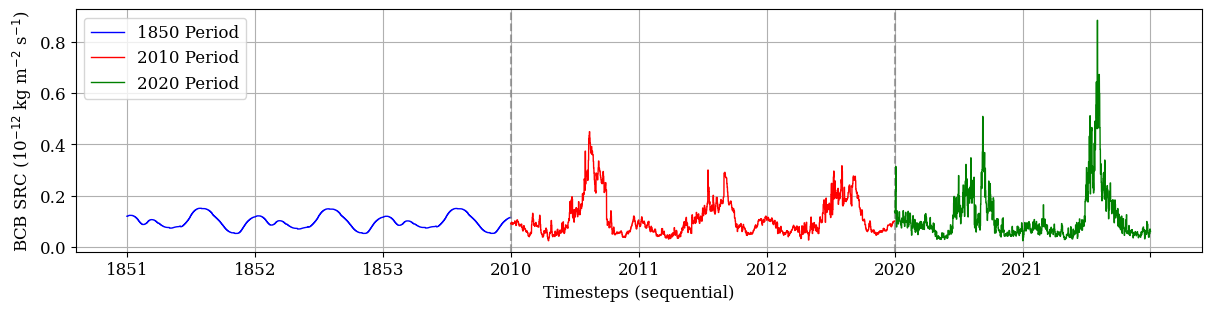

In [36]:
# Calculate spatial averages for each dataset
ds_1850_avg = ds_1850['BCB_biomass_src'].weighted(weights).mean(dim=['lat', 'lon'])
ds_2010_avg = ds_2010['BCB_biomass_src'].weighted(weights).mean(dim=['lat', 'lon'])
ds_2020_avg = ds_2020['BCB_biomass_src'].weighted(weights).mean(dim=['lat', 'lon'])

# Create the figure with actual day numbers
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 3), constrained_layout=True)

# Define colors for each period
colors = ['blue', 'red', 'green']
labels = ['1850 Period', '2010 Period', '2020 Period']
data_arrays = [ds_1850_avg, ds_2010_avg, ds_2020_avg]

# Start from day 0
current_day = 0
all_days = []
all_values = []
all_colors = []

# Process each dataset
for i, (data, label, color) in enumerate(zip(data_arrays, labels, colors)):
    days = np.arange(current_day, current_day + len(data))
    current_day += len(data)
    
    ax.plot(days, data.values, color=color, label=label, linewidth=1)
    
    # Store for multi-color line if needed
    all_days.extend(days)
    all_values.extend(data.values)
    all_colors.extend([color] * len(data))
    
    # Add separator line
    if i < len(data_arrays) - 1:
        ax.axvline(x=current_day, color='gray', linestyle='--', alpha=0.7)

ax.set_xticks([0, 17520, 35040, 52560, 70080, 87600, 105120, 122640, 140160])
ax.set_xticklabels(['1851', '1852', '1853', '2010', '2011', '2012', '2020', '2021', ''])

# Set titles and labels
ax.set_xlabel('Timesteps (sequential)')
ax.set_ylabel(r'BCB SRC (10$^{-12}$ kg m$^{-2}$ s$^{-1}$)')
ax.grid()
ax.legend()

plt.savefig(f'bcb_src.png', dpi=300)
plt.show()

In [5]:
for root, dirs, files in os.walk('/home/serfani/serfani_data1/E3OMA1850'):
    
    sorted_files = sorted(files)
    list_1850_bcb = [os.path.join(root, file) for file in sorted_files if file.split(".")[1] == 'taijlh1E3oma']
    list_1850_frc = [os.path.join(root, file) for file in sorted_files if file.split(".")[1] == 'aijlh1E3oma']   # Velocity Fields (time, level, lat, lon)

for root, dirs, files in os.walk('/home/serfani/serfani_data1/E3OMA2010D'):
    
    sorted_files = sorted(files)
    list_2010_bcb = [os.path.join(root, file) for file in sorted_files if file.split(".")[1] == 'taijlh1E3oma']
    list_2010_frc = [os.path.join(root, file) for file in sorted_files if file.split(".")[1] == 'aijlh1E3oma']   # Velocity Fields (time, level, lat, lon)

for root, dirs, files in os.walk('/home/serfani/serfani_data1/E3OMA2020D'):
    
    sorted_files = sorted(files)
    list_2020_bcb = [os.path.join(root, file) for file in sorted_files if file.split(".")[1] == 'taijlh1E3oma']
    list_2020_frc = [os.path.join(root, file) for file in sorted_files if file.split(".")[1] == 'aijlh1E3oma']   # Velocity Fields (time, level, lat, lon)


In [6]:
ds_1851_bcb = xr.open_mfdataset(list_1850_bcb[1*365:2*365], combine='by_coords')
ds_1852_bcb = xr.open_mfdataset(list_1850_bcb[2*365:3*365], combine='by_coords')
ds_1853_bcb = xr.open_mfdataset(list_1850_bcb[3*365:4*365], combine='by_coords')
ds_2010_bcb = xr.open_mfdataset(list_2010_bcb[0*365:1*365], combine='by_coords')
ds_2011_bcb = xr.open_mfdataset(list_2010_bcb[1*365:2*365], combine='by_coords')
ds_2012_bcb = xr.open_mfdataset(list_2010_bcb[2*365:3*365], combine='by_coords')
ds_2020_bcb = xr.open_mfdataset(list_2020_bcb[0*365:1*365], combine='by_coords')
ds_2021_bcb = xr.open_mfdataset(list_2020_bcb[1*365:2*365], combine='by_coords')

In [6]:
ds_1851_frc = xr.open_mfdataset(list_1850_frc[1*365:2*365], combine='by_coords')
ds_1852_frc = xr.open_mfdataset(list_1850_frc[2*365:3*365], combine='by_coords')
ds_1853_frc = xr.open_mfdataset(list_1850_frc[3*365:4*365], combine='by_coords')
ds_2010_frc = xr.open_mfdataset(list_2010_frc[0*365:1*365], combine='by_coords')
ds_2011_frc = xr.open_mfdataset(list_2010_frc[1*365:2*365], combine='by_coords')
ds_2012_frc = xr.open_mfdataset(list_2010_frc[2*365:3*365], combine='by_coords')
ds_2020_frc = xr.open_mfdataset(list_2020_frc[0*365:1*365], combine='by_coords')
ds_2021_frc = xr.open_mfdataset(list_2020_frc[1*365:2*365], combine='by_coords')

In [ ]:
# Add name attributes to each dataset
ds_1851_bcb.attrs['name'] = '1851'; ds_1851_frc.attrs['name'] = '1851'
ds_1852_bcb.attrs['name'] = '1852'; ds_1852_frc.attrs['name'] = '1852'
ds_1853_bcb.attrs['name'] = '1853'; ds_1853_frc.attrs['name'] = '1853'
ds_2010_bcb.attrs['name'] = '2010'; ds_2010_frc.attrs['name'] = '2010'
ds_2011_bcb.attrs['name'] = '2011'; ds_2011_frc.attrs['name'] = '2011'
ds_2012_bcb.attrs['name'] = '2012'; ds_2012_frc.attrs['name'] = '2012'
ds_2020_bcb.attrs['name'] = '2020'; ds_2020_frc.attrs['name'] = '2020'
ds_2021_bcb.attrs['name'] = '2021'; ds_2021_frc.attrs['name'] = '2021'

In [9]:
R_d = 287.055 # Specific gas constant for dry air in J/(kg·K)

ds_1851_bcb['BCB_conc'] = ds_1851_bcb['BCB'] * ds_1851_frc['p_3d'] / (R_d * ds_1851_frc['t'])
ds_1851_bcb['BCB_conc'].attrs['units'] = 'micrograms per cubic meter (μg/m^3)'
ds_1851_bcb['BCB_conc'].attrs['long_name'] = 'BCB Conc.'


ds_1852_bcb['BCB_conc'] = ds_1852_bcb['BCB'] * ds_1852_frc['p_3d'] / (R_d * ds_1852_frc['t'])
ds_1852_bcb['BCB_conc'].attrs['units'] = 'micrograms per cubic meter (μg/m^3)'
ds_1852_bcb['BCB_conc'].attrs['long_name'] = 'BCB Conc.'

ds_1853_bcb['BCB_conc'] = ds_1853_bcb['BCB'] * ds_1853_frc['p_3d'] / (R_d * ds_1853_frc['t'])
ds_1853_bcb['BCB_conc'].attrs['units'] = 'micrograms per cubic meter (μg/m^3)'
ds_1853_bcb['BCB_conc'].attrs['long_name'] = 'BCB Conc.'

ds_2010_bcb['BCB_conc'] = ds_2010_bcb['BCB'] * ds_2010_frc['p_3d'] / (R_d * ds_2010_frc['t'])
ds_2010_bcb['BCB_conc'].attrs['units'] = 'micrograms per cubic meter (μg/m^3)'
ds_2010_bcb['BCB_conc'].attrs['long_name'] = 'BCB Conc.'

ds_2011_bcb['BCB_conc'] = ds_2011_bcb['BCB'] * ds_2011_frc['p_3d'] / (R_d * ds_2011_frc['t'])
ds_2011_bcb['BCB_conc'].attrs['units'] = 'micrograms per cubic meter (μg/m^3)'
ds_2011_bcb['BCB_conc'].attrs['long_name'] = 'BCB Conc.'

ds_2012_bcb['BCB_conc'] = ds_2012_bcb['BCB'] * ds_2012_frc['p_3d'] / (R_d * ds_2012_frc['t'])
ds_2012_bcb['BCB_conc'].attrs['units'] = 'micrograms per cubic meter (μg/m^3)'
ds_2012_bcb['BCB_conc'].attrs['long_name'] = 'BCB Conc.'

ds_2020_bcb['BCB_conc'] = ds_2020_bcb['BCB'] * ds_2020_frc['p_3d'] / (R_d * ds_2020_frc['t'])
ds_2020_bcb['BCB_conc'].attrs['units'] = 'micrograms per cubic meter (μg/m^3)'
ds_2020_bcb['BCB_conc'].attrs['long_name'] = 'BCB Conc.'

ds_2021_bcb['BCB_conc'] = ds_2021_bcb['BCB'] * ds_2021_frc['p_3d'] / (R_d * ds_2021_frc['t'])
ds_2021_bcb['BCB_conc'].attrs['units'] = 'micrograms per cubic meter (μg/m^3)'
ds_2021_bcb['BCB_conc'].attrs['long_name'] = 'BCB Conc.'

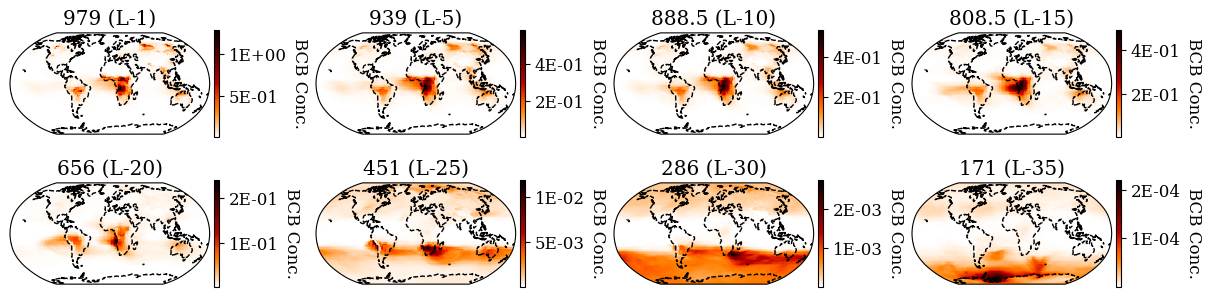

In [25]:
# ds_avg = ds_2012_bcb['BCB_conc'].weighted(weights).mean(dim=("time")).compute()

fig, axs = plt.subplots(ncols=4, nrows=2, figsize=(12, 3), constrained_layout=True, subplot_kw={'projection': ccrs.Robinson()})

# Define the plm values
plm = [979, 969, 959, 949, 939, 929, 919, 909, 899, 888.5, 877, 864, 848.5, 830, 808.5, 784, 756.5, 726, 692.5, 656, 616.5, 574, 531, 490, 451, 414, 379, 346, 315, 286, 259, 234, 211, 190, 171, 154, 139, 126, 115, 105, 95, 85, 75.5, 67, 59.5, 53, 47.5, 42.5, 37.5, 32.5, 27.5, 22.5, 17.5, 12.5, 7.81, 4.39, 2.47, 1.39, 0.781, 0.439, 0.247, 0.139]

# Define the levels to plot (subtract 1 for 0-based indexing)
levels_to_plot = [0, 4, 9, 14, 19, 24, 29, 34]  # Level 1, 5, 10, 15, 20, 25, 30, 35
level_labels = [1, 5, 10, 15, 20, 25, 30, 35]

for idx, ax in enumerate(axs.flat):
    # Plot the data without automatic colorbar
    im = ds_avg.isel(level=levels_to_plot[idx]).plot(ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, cmap='gist_heat_r')
    
    # Add custom colorbar with scientific notation and custom title
    cbar = plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02, format='%.E')
    cbar.set_label('BCB Conc.', rotation=270, labelpad=15)
    
    # Add coastlines and borders
    ax.add_feature(cfeature.COASTLINE, linestyle='--')
    
    # Set title with plm value and level
    plm_value = plm[levels_to_plot[idx]]
    ax.set_title(f'{plm_value} (L-{level_labels[idx]})')

plt.savefig('fig-01.png', dpi=300)
plt.show()

In [ ]:
for ds in [ds_2020_bcb, ds_2021_bcb]:
    ds_avg_ = ds['BCB_conc'].weighted(weights).mean(dim=("lat", "lon", "time")).compute()

    # Define the plm values
    plm = [979, 969, 959, 949, 939, 929, 919, 909, 899, 888.5, 877, 864, 848.5, 830, 808.5, 784, 756.5, 726, 692.5, 656, 616.5, 574, 
           531, 490, 451, 414, 379, 346, 315, 286, 259, 234, 211, 190, 171, 154, 139, 126, 115, 105, 95, 85, 75.5, 67, 59.5, 53, 47.5, 
           42.5, 37.5, 32.5, 27.5, 22.5, 17.5, 12.5, 7.81, 4.39, 2.47, 1.39, 0.781, 0.439, 0.247, 0.139]

    # Create the figure with subplots
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4, 5), constrained_layout=True)

    # Plot BCB in the top row
    ds_avg_.plot(ax=ax, y='level', yincrease=True, color='green', linewidth=1)

    ax.set_xlabel(r'BCB Conc. (μg/m$^3$)')
    ax.set_ylabel('Vertical Pressure Level (hPa)')

    # Set y-axis range to match your dataset's level range (1-62)
    ax.set_ylim(0, 63)
    
    # Set y-ticks and labels with pressure values
    # Using 1-based indices to match your dataset
    tick_levels = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]
    tick_labels = [plm[i-1] for i in tick_levels]  # Adjusting for 0-based array index
    
    ax.set_yticks(tick_levels)
    ax.set_yticklabels(tick_labels)
    
    # Limit x-axis to 4 ticks
#     ax.set_xticks([0, 0.01, 0.02, 0.03])

    # Add grid to all subplots
    ax.grid(linestyle='--', alpha=0.7)

    plt.savefig(f'bcb_{ds.attrs["name"]}.png', dpi=300)
    plt.show()

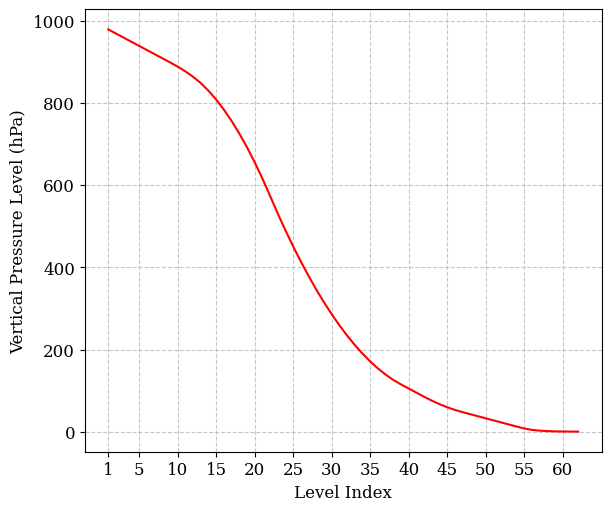

In [22]:
for ds in [ds_2012_frc]:
    # ds_avg_ = ds['p_3d'].weighted(weights).mean(dim=("lat", "lon", "time")).compute()

    # Create the figure with subplots
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 5), constrained_layout=True)

    ds_avg_.plot(ax=ax, color='red', linewidth=1.5)

    ax.set_xlabel('Level Index')
    ax.set_ylabel('Vertical Pressure Level (hPa)')

    tick_levels = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]  
    ax.set_xticks(tick_levels)

    # Add grid to all subplots
    ax.grid(linestyle='--', alpha=0.7)

    plt.savefig('pressure_level.png', dpi=300)
    plt.show()